# Machine Learning -- Jour 5
## OpenCV a YOLO: voir et comprendre une image

**Master GI3 -- Approche Probleme / Solution**

Objectifs:
- Comprendre la representation d'une image( pixels, canaux, tableau Numpy)
- Maitriser les operations ded base OpenCV: charger, manipuler, annoter
- Utiliser YOLOv8 pour detecter des objectifs en quelques lignes de code

---

## 0. Mise en place

1. Installer les bibliotheques si besoin: 'pip install opencv-python ultralytics'
2. Placez 'scene_rue.jpg' (fournie par l'enseignant dans le meme dossier que ce notebook.)
3. La premiere execution de YOLO telechargera automatiquement le modele(6 Mo).
   ** Une connexion internet est necessaire.**

In [7]:
import os

fichiers= ["scene_rue.jpg"]
for f in fichiers:
    if os.path.exists(f):
        print(f"Fichier trouve: {f}")
    else:
        print(f"Fichier INTROUVABLE : {f} --verifiez son emplacement")

Fichier trouve: scene_rue.jpg


## 1. Le probleme

On veut detecter automatiquement les objets presents dans une image de rue(personnes, voitures, panneaux....) et localiser chacun d'eux

## 2. Premiere tentative : lire une image sans outil specialise

In [8]:
from PIL import Image
import numpy as np

img_pil= Image.open("scene_rue.jpg")
tableau= np.array(img_pil)

print("Forme :", tableau.shape) #(hauteur, largeur, canaux)
print("Type :", tableau.dtype)
print("Pixel [0,0]:", tableau[0,0]) # [R, G, B] du premier pixel

Forme : (480, 640, 3)
Type : uint8
Pixel [0,0]: [140 148 169]


Une image couleur 480x640 est un tableau Numpy de forme **(480, 640,3)** : 480 lignes, 640 colonnes, 3 valeurs par pixel (Rouge,Vert,Bleu), entre 0 et 255.

** Le probleme: ** detecter des objets par objets par des regles sur les pixels est impossible -- un objet change d'apparence selon l'eclairage, la distance, l'angle. Il faut un modele appris.

## 3. OpenCV : manipuler une image

### 3.1 Charger et afficher

Forme OpenCV: (480, 640, 3)
Type : uint8
<class 'numpy.ndarray'>


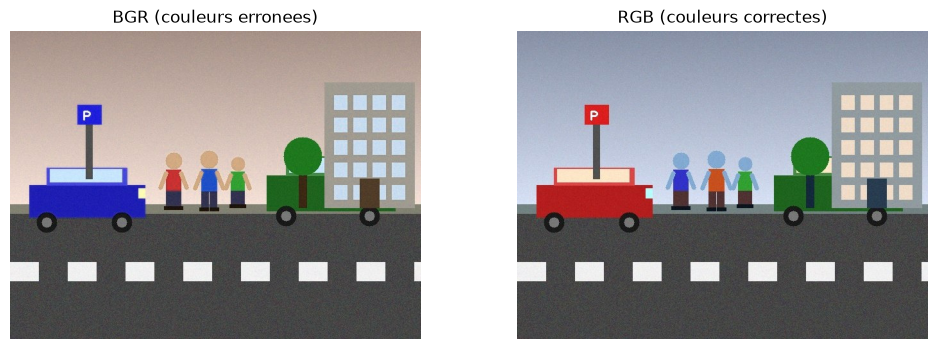

In [9]:
import cv2
import matplotlib.pyplot as plt

img= cv2.imread("scene_rue.jpg")
print("Forme OpenCV:", img.shape) # (480, 640, 3) -- BGR !
print("Type :", img.dtype)
print(type(img))
#print(img)

# OpenCV charge en BGR -> convertir en BGR pour Matplotlib
fig, axes= plt.subplots(1,2, figsize=(12,4))
axes[0].imshow(img)       # mauvaises couleurs
axes[0].set_title("BGR (couleurs erronees)")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))       # correct
axes[1].set_title("RGB (couleurs correctes)")
axes[1].axis("off")

plt.show()

### 3.2 Redimensionner, convertir en gris, rogner

Redimensionne : (240, 320, 3)
Niveaux de gris : (480, 640)
Region rognee : (150, 200, 3)


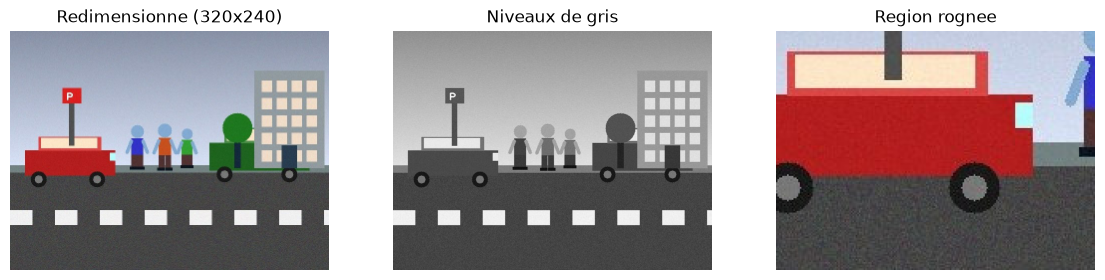

In [ ]:
# Redimensionner -- attention : cv2.resize attend (largeur, hauteur)
img_small = cv2.resize(img, (320, 240))
print("Redimensionne :", img_small.shape) # (240, 320, 3)
# Niveaux de gris
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print("Niveaux de gris :", img_gray.shape) # (480, 640) -- 1 canal
# Rogner une region : img[lignes, colonnes]
region = img[200:350, 50:250].copy()
print("Region rognee :", region.shape)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(cv2.cvtColor(img_small, cv2.COLOR_BGR2RGB))
axes[0].set_title("Redimensionne (320x240)")
axes[0].axis("off")

axes[1].imshow(img_gray, cmap="gray")
axes[1].set_title("Niveaux de gris")
axes[1].axis("off")

axes[2].imshow(cv2.cvtColor(region, cv2.COLOR_BGR2RGB))
axes[2].set_title("Region rognee")
axes[2].axis("off")
plt.show()


image 1/1 /home/rwan-alex/Machine Learning/jour5_ML/scene_rue.jpg: 480x640 1 truck, 95.3ms
Speed: 1.0ms preprocess, 95.3ms inference, 1.0ms postprocess per image at shape (1, 3, 480, 640)


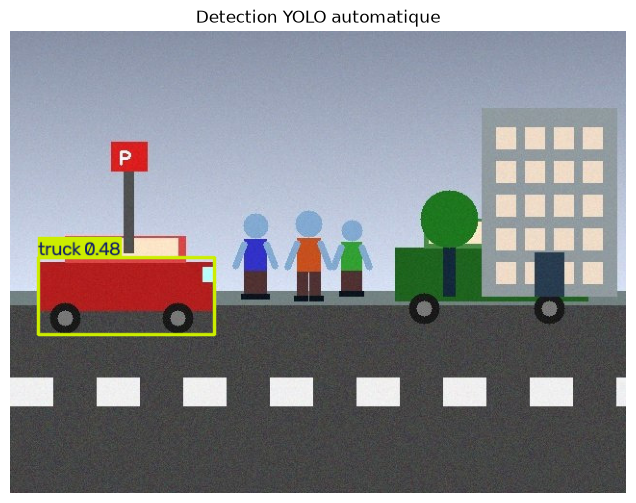

In [11]:
from ultralytics import YOLO

#charger le modele pre-entraine (telechargement auto la 1ere fois, '6 Mo')
modele= YOLO("yolov8n.pt")

#Appliquer sur l'Image
resultats= modele("scene_rue.jpg", conf=0.25)

#Afficher le resultat annote
img_yolo= resultats[0].plot()  #tableau BGR avec toutes les boites

fig, ax= plt.subplots(figsize=(10,6))
ax.imshow(cv2.cvtColor(img_yolo, cv2.COLOR_BGR2RGB))

ax.set_title("Detection YOLO automatique")
ax.axis("off")
plt.show()

In [12]:
for r in resultats:
    print(f"Objets detectes: {len(r.boxes)}")
    for box in r.boxes:
        cls_id= int(box.cls[0])
        cls_nom= modele.names[cls_id]
        conf= float(box.conf[0])
        x1,y1,x2,y2= map(int, box.xyxy[0])
        print(f"{cls_nom: 15s} confiance= {conf: .0%} position=({x1},{y1})->({x2},{y2})")

Objets detectes: 1


ValueError: Space not allowed in string format specifier